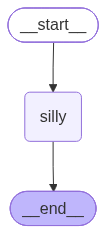

In [20]:

import os
import random
import requests
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
import gradio as gr
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
# from langgraph.checkpoint.sqlite import SqliteSaver

load_dotenv(override=True)


class State(TypedDict):
    messages: Annotated[list, add_messages]

nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Eels", "Pickles"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "sparkly", "haunted"]

def silly_node(state: State) -> dict:
    sentence = f"{random.choice(nouns)} are {random.choice(adjectives)}"
    return {"messages": [{"role": "assistant", "content": sentence}]}

builder = StateGraph(State)
builder.add_node("silly", silly_node)
builder.add_edge(START, "silly")
builder.add_edge("silly", END)

graph = builder.compile()


display(Image(graph.get_graph().draw_mermaid_png()))


In [21]:
result = graph.invoke({"messages":[{"role": "user", "content": "say something"}]})
result

{'messages': [HumanMessage(content='say something', additional_kwargs={}, response_metadata={}, id='39cd2c93-9987-4dcf-8593-bb2639330c2a'),
  AIMessage(content='Cabbages are existential', additional_kwargs={}, response_metadata={}, id='884e127f-33f4-4ec4-857d-777121f02f73', tool_calls=[], invalid_tool_calls=[])]}

In [22]:
print(result["messages"][-1].content)

Cabbages are existential


In [23]:
llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-4o-mini"),
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL", "https://api.gapgpt.app/v1"),
)

In [24]:
def chatbot_node(state: State) -> dict:
    return {"messages": [llm.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile()

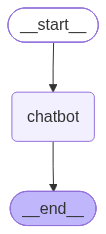

In [25]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
result = graph.invoke({"messages": [{"role": "user", "content": "is ayatollah khamenei alive?"}]})
print(result["messages"][-1].content)

In [ ]:
result

In [26]:
import json

In [27]:
@tool
def langsearch(query: str) -> str:
    """Search the web for current information and return source URLs with context."""
    response = requests.post(
        "https://api.langsearch.com/v1/web-search",
        headers={
            "Authorization": f"Bearer {os.environ['LANGSEARCH_API_KEY']}",
            "Content-Type": "application/json",
        },
        json={
            "query": query,
            "count": 5,
            "contents": {"text": True},
            "freshness": "noLimit",
        },
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    sources = [
        {
            "title": item.get("name"),
            "url": item["url"],
            "context": item.get("text") or item.get("snippet") or "",
        }
        for item in payload["data"]["webPages"]["value"]
    ]
    return json.dumps({"sources": sources}, ensure_ascii=False)


In [28]:
from dotenv import load_dotenv
load_dotenv(override=True)

# after your langsearch definition:
result = langsearch.invoke({"query": "is ayatollah khamenei alive?"})

In [29]:
data = json.loads(result)
urls = [s["url"] for s in data["sources"]]
urls

['https://www.gistreel.com/is-ayatollah-still-alive',
 'https://theconservativetreehouse.com/blog/2026/02/28/conflicting-reports-is-irans-supreme-leader-ali-khamenei-alive-or-dead/',
 'https://www.dynamitenews.com/international/khamenei-alive-says-iran-foreign-minister-amid-reports-of-death-after-us-israel-strikes',
 'https://leadstories.com/hoax-alert/2026/02/fact-check-iranian-supreme-leader-ayatollah-ali-khamenei-did-not-address-the-world-after-reports-of-his-death.html',
 'https://economictimes.indiatimes.com/topic/amir-nasirzadeh']

In [30]:
!pip -q install scrapegraphai nest_asyncio


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [31]:
import json
from scrapegraphai.graphs import SmartScraperGraph

import nest_asyncio
nest_asyncio.apply()

# 1) search
raw = langsearch.invoke({"query": "is ayatollah khamenei alive?"})
data = json.loads(raw)
urls = [s["url"] for s in data["sources"]]

# 2) scrape one page (or loop over urls)
graph_config = {
    "llm": {
        "api_key": os.getenv("OPENAI_API_KEY"),
        "model": "openai/gpt-4o",          # scrapegraph uses provider/model form
        "base_url": os.getenv("OPENAI_BASE_URL"),  # GapGPT: https://api.gapgpt.app/v1
    },
    "verbose": True,
    "headless": True,
}

smart = SmartScraperGraph(
    prompt="Extract claims about whether Khamenei is alive or dead, who said what, and dates. Return JSON.",
    source=urls[0],   # one URL from LangSearch
    config=graph_config,
)
result = smart.run()
print(result)

--- Executing Fetch Node ---
--- (Fetching HTML from: https://www.gistreel.com/is-ayatollah-still-alive) ---
Attempt 1 failed: BrowserType.launch: Executable doesn't exist at /home/mohmd/.cache/ms-playwright/chromium_headless_shell-1243/chrome-headless-shell-linux64/chrome-headless-shell
╔════════════════════════════════════════════════════════════╗
║ Looks like Playwright was just installed or updated.       ║
║ Please run the following command to download new browsers: ║
║                                                            ║
║     playwright install                                     ║
║                                                            ║
║ <3 Playwright Team                                         ║
╚════════════════════════════════════════════════════════════╝


RuntimeError: Failed to scrape after 1 attempts: BrowserType.launch: Executable doesn't exist at /home/mohmd/.cache/ms-playwright/chromium_headless_shell-1243/chrome-headless-shell-linux64/chrome-headless-shell
╔════════════════════════════════════════════════════════════╗
║ Looks like Playwright was just installed or updated.       ║
║ Please run the following command to download new browsers: ║
║                                                            ║
║     playwright install                                     ║
║                                                            ║
║ <3 Playwright Team                                         ║
╚════════════════════════════════════════════════════════════╝

In [ ]:
!python -m playwright install --list

In [32]:
import json
import os
import requests
from bs4 import BeautifulSoup
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv(override=True)

llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-4o"),
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL", "https://api.gapgpt.app/v1"),
)

query = "is ayatollah khamenei alive?"

# 1) search
raw = langsearch.invoke({"query": query})
data = json.loads(raw)
sources = data["sources"]

print("Found URLs:")
for s in sources:
    print("-", s["url"])

# 2) fetch first page with requests (no Playwright)
url = sources[0]["url"]
try:
    html = requests.get(url, timeout=30, headers={"User-Agent": "Mozilla/5.0"}).text
    page_text = BeautifulSoup(html, "html.parser").get_text(" ", strip=True)[:8000]
except Exception as e:
    print("Fetch failed, using LangSearch context:", e)
    page_text = sources[0].get("context", "")

# 3) ask LLM
prompt = f"""Based on these sources, answer: {query}

Source URL: {url}
Page text:
{page_text}

Also use these search snippets:
{json.dumps(sources, ensure_ascii=False, indent=2)}

Give a short answer with conflicting claims and cite URLs.
"""

answer = llm.invoke(prompt)
print("\n=== ANSWER ===")
print(answer.content)


Found URLs:
- https://www.gistreel.com/is-ayatollah-still-alive
- https://theconservativetreehouse.com/blog/2026/02/28/conflicting-reports-is-irans-supreme-leader-ali-khamenei-alive-or-dead/
- https://www.dynamitenews.com/international/khamenei-alive-says-iran-foreign-minister-amid-reports-of-death-after-us-israel-strikes
- https://leadstories.com/hoax-alert/2026/02/fact-check-iranian-supreme-leader-ayatollah-ali-khamenei-did-not-address-the-world-after-reports-of-his-death.html
- https://economictimes.indiatimes.com/topic/amir-nasirzadeh
Fetch failed, using LangSearch context: HTTPSConnectionPool(host='www.gistreel.com', port=443): Max retries exceeded with url: /is-ayatollah-still-alive (Caused by NewConnectionError("HTTPSConnection(host='www.gistreel.com', port=443): Failed to establish a new connection: [Errno 101] Network is unreachable"))

=== ANSWER ===
There are conflicting reports regarding whether Ayatollah Ali Khamenei is alive. Some sources, such as Iran's foreign minister 

In [ ]:
# ScrapeGraphAI with your local Chrome (skips blocked playwright CDN)
import json
import os
from pathlib import Path

import nest_asyncio
from scrapegraphai.graphs import SmartScraperGraph

nest_asyncio.apply()

CHROME = str(Path.home() / ".cache/ms-playwright/chromium-1243/chrome-linux64/chrome")
assert Path(CHROME).exists(), f"Chrome not found at {CHROME}"

query = "is ayatollah khamenei alive?"
prompt = "Extract claims about whether Khamenei is alive or dead, who said what, and dates. Return JSON."
raw = langsearch.invoke({"query": query})
sources = json.loads(raw)["sources"]

graph_config = {
    "llm": {
        "api_key": os.getenv("OPENAI_API_KEY"),
        "model": f"openai/{os.getenv('OPENAI_MODEL', 'gpt-4o')}",
        "base_url": os.getenv("OPENAI_BASE_URL", "https://api.gapgpt.app/v1"),
    },
    "verbose": True,
    "headless": True,
    "loader_kwargs": {
        "executable_path": CHROME,  # use local chrome-linux64.zip
        "timeout": 60,
    },
}

result = None
for s in sources:
    print("Trying:", s["url"])
    try:
        result = SmartScraperGraph(prompt=prompt, source=s["url"], config=graph_config).run()
        break
    except Exception as e:
        print("Failed:", e)

if result is None:
    # fallback: scrape LangSearch text as a local HTML file
    html_path = Path("/tmp/langsearch_fallback.html")
    html_path.write_text(f"<html><body><pre>{sources[0]['context']}</pre></body></html>", encoding="utf-8")
    result = SmartScraperGraph(prompt=prompt, source=str(html_path), config=graph_config).run()

print(json.dumps(result, indent=2, ensure_ascii=False) if isinstance(result, (dict, list)) else result)
